# Classification binaire – Diabète (Pima Indians)
Régression logistique **implémentée from scratch** (NumPy) sur 3 caractéristiques : Glucose, BMI, Age.
Scikit-learn n'est utilisé que pour la séparation train/test et la matrice de confusion.

## 1. Imports

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

%matplotlib inline
np.random.seed(42)

## 2. Chargement des données

In [36]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
col_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
             'BMI', 'DiabetesPedigree', 'Age', 'Outcome']
data_complete = pd.read_csv(url, names=col_names)
data_complete.shape

(768, 9)

## 3. Sélection des caractéristiques

In [37]:
features_selection = ['Glucose', 'BMI', 'Age']
X = data_complete[features_selection]
y = data_complete['Outcome']

df_real = X.copy()
df_real['Diabete'] = y.map({0: 'Non', 1: 'Oui'})

print("=== APERÇU DE LA DATASET RÉELLE ===")
print(df_real.head())

=== APERÇU DE LA DATASET RÉELLE ===
   Glucose   BMI  Age Diabete
0      148  33.6   50     Oui
1       85  26.6   31     Non
2      183  23.3   32     Oui
3       89  28.1   21     Non
4      137  43.1   33     Oui


## 4. Visualisation 3D

In [38]:
fig = px.scatter_3d(df_real, x='Glucose', y='BMI', z='Age', color='Diabete',
                    title="Distribution réelle du diabète (3 caractéristiques)",
                    labels={'Diabete': 'Statut diabète'},
                    color_discrete_map={'Non': 'green', 'Oui': 'red'})
fig.show()

## 5. Séparation train / test et standardisation

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardisation avec la moyenne / l'écart-type du train uniquement
mu = X_train.mean().values
sigma = X_train.std().values
X_train_s = ((X_train - mu) / sigma).values
X_test_s = ((X_test - mu) / sigma).values

# y en colonnes (n, 1) pour être cohérent avec la sortie du modèle
y_train_np = y_train.values.reshape(-1, 1)
y_test_np = y_test.values.reshape(-1, 1)

print('X_train :', X_train_s.shape, '| y_train :', y_train_np.shape)
print('X_test  :', X_test_s.shape, '| y_test  :', y_test_np.shape)

X_train : (614, 3) | y_train : (614, 1)
X_test  : (154, 3) | y_test  : (154, 1)


## 6. Modèle (from scratch)

### 6.1 Fonction sigmoïde

In [40]:
def sigmoid(x):
    x = np.clip(x, -500, 500)  # évite le débordement de np.exp
    return 1 / (1 + np.exp(-x))

### 6.2 Initialisation et modèle

In [41]:
def initialisation(X):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return (W, b)


def modele(X, W, b):
    Z = X.dot(W) + b
    A = sigmoid(Z)
    return A

### 6.3 Fonction coût (log loss)

In [42]:
def log_loss(y, A, eps=1e-15):
    A = np.clip(A, eps, 1 - eps)  # évite log(0)
    return 1 / len(y) * np.sum(-y * np.log(A) - (1 - y) * np.log(1 - A))

### 6.4 Gradients et descente de gradient

In [43]:
def gradients(X, A, y):
    dW = 1 / len(y) * np.dot(X.T, A - y)
    db = 1 / len(y) * np.sum(A - y)
    return (dW, db)


def optimisation(X, W, b, A, y, learning_rate):
    dW, db = gradients(X, A, y)
    W = W - learning_rate * dW
    b = b - learning_rate * db
    return (W, b)

### 6.5 Prédiction

In [44]:
def predict(X, W, b, seuil=0.5):
    A = modele(X, W, b)
    return A >= seuil

### 6.6 Modèle final

In [45]:
def regression_logistique(X, y, learning_rate=0.1, n_iter=1000):
    # Initialisation
    W, b = initialisation(X)
    loss_history = []

    # Entraînement
    for i in range(n_iter):
        A = modele(X, W, b)
        loss_history.append(log_loss(y, A))
        W, b = optimisation(X, W, b, A, y, learning_rate=learning_rate)

    # Courbe de la fonction coût
    plt.plot(loss_history)
    plt.xlabel('n_iteration')
    plt.ylabel('Log_loss')
    plt.title('Evolution des erreurs')
    plt.show()
    return W, b

## 7. Entraînement

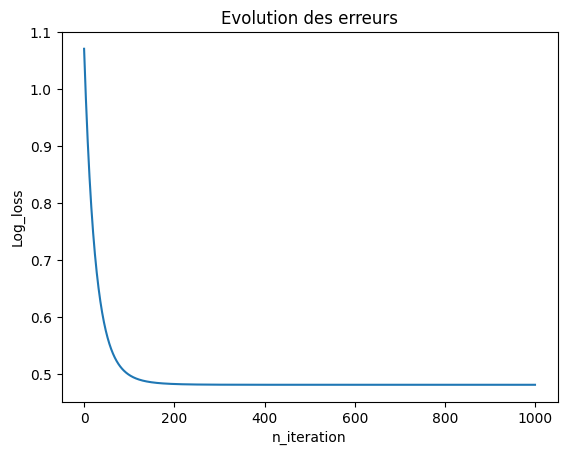

W = [0.9913412  0.73304843 0.5023258 ] | b = [-0.88095506]


In [46]:
W, b = regression_logistique(X_train_s, y_train_np)
print('W =', W.ravel(), '| b =', b)

## 8. Évaluation

In [47]:
y_train_pred = predict(X_train_s, W, b)
y_test_pred = predict(X_test_s, W, b)

# Accuracy calculée à la main
acc_train = np.mean(y_train_pred == y_train_np)
acc_test = np.mean(y_test_pred == y_test_np)
print(f"Accuracy train : {acc_train:.2%}")
print(f"Accuracy test  : {acc_test:.2%}")

Accuracy train : 77.20%
Accuracy test  : 74.68%


### Matrice de confusion (scikit-learn)

In [48]:
cm_train = confusion_matrix(y_train_np, y_train_pred)
cm_test = confusion_matrix(y_test_np, y_test_pred)
print("Matrice de confusion (train) :", cm_train, sep=chr(10))
print("Matrice de confusion (test) :", cm_test, sep=chr(10))

Matrice de confusion (train) :
[[352  49]
 [ 91 122]]
Matrice de confusion (test) :
[[80 19]
 [20 35]]


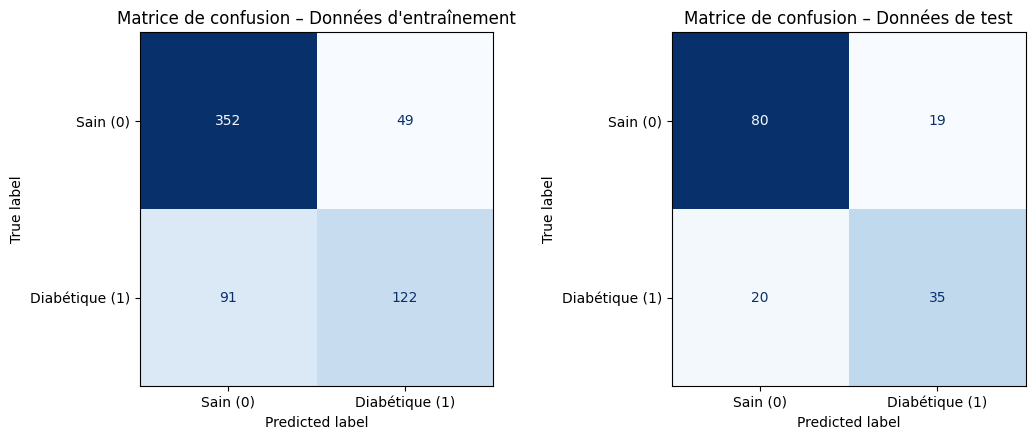

In [49]:
labels = ['Sain (0)', 'Diabétique (1)']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cm, titre in zip(axes, [cm_train, cm_test], ["Données d'entraînement", "Données de test"]):
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matrice de confusion – {titre}')
plt.tight_layout()
plt.show()

## 9. Plan de séparation en 3D
Le plan est la frontière de décision `w1·Glucose + w2·BMI + w3·Age + b = 0` (probabilité = 0.5).

In [50]:
# Retour des poids de l'espace standardisé vers l'espace d'origine
w = W.ravel() / sigma
b0 = (b - np.sum(W.ravel() * mu / sigma)).item()
w1, w2, w3 = w

# Grille (Glucose, BMI) -> Age du plan : Age = -(w1*Glucose + w2*BMI + b0) / w3
g = np.linspace(X['Glucose'].min(), X['Glucose'].max(), 30)
m = np.linspace(X['BMI'].min(), X['BMI'].max(), 30)
G, M = np.meshgrid(g, m)
A = -(w1 * G + w2 * M + b0) / w3

# Ne garder que la partie du plan dans l'intervalle des âges
A = np.where((A >= X['Age'].min()) & (A <= X['Age'].max()), A, np.nan)

In [51]:
fig = px.scatter_3d(df_real, x='Glucose', y='BMI', z='Age', color='Diabete',
                    title="Séparation du diabète par un plan (régression logistique)",
                    color_discrete_map={'Non': 'green', 'Oui': 'red'})
fig.update_traces(marker=dict(size=3))
fig.add_trace(go.Surface(x=G, y=M, z=A, opacity=0.5, showscale=False,
                         colorscale=[[0, 'royalblue'], [1, 'royalblue']],
                         name='Plan de séparation'))
fig.update_layout(scene=dict(zaxis=dict(range=[X['Age'].min(), X['Age'].max()])))
fig.show()